# Junior Data Analyst: data analysis and anomaly detection in part images

**Background:** parts are photographed at the end of production and a human inspector labelled some images as
OK (0) or defective (1). Alerts went up recently, and it is unclear whether the cause is **part quality**,
**imaging conditions**, or **the data/labels themselves**.

**Goal:** explore the data and images, build a simple and explainable first-pass detector for suspicious images,
validate it honestly, and draw conclusions.

**How to run:** from this folder, *Run All* (or `jupyter nbconvert --to notebook --execute --inplace solution.ipynb`).
Needs numpy, pandas, opencv-python, matplotlib and scikit-learn; runs on a CPU in under a minute.

In [1]:
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(".")
SEED = 42
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def read_gray(rel_path):
    # cv2.imread fails on Windows paths with non-ASCII characters (e.g. a Hebrew folder name),
    # so read the bytes with numpy and decode them with OpenCV.
    return cv2.imdecode(np.fromfile(str(DATA_DIR / rel_path), np.uint8), cv2.IMREAD_GRAYSCALE)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, " test:", test.shape)
display(train.head())

train: (168, 10)  test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


## Part A: getting to know the data

### Data quality checks
Before any analysis: missing values, duplicate IDs, overlap between train and test, and whether every image file exists.

In [2]:
checks = {
    "missing values (train)": int(train.isna().sum().sum()),
    "missing values (test)": int(test.isna().sum().sum()),
    "duplicate image_id (train)": int(train.image_id.duplicated().sum()),
    "image_id in both train and test": len(set(train.image_id) & set(test.image_id)),
    "image files missing on disk": int(sum(not (DATA_DIR / f).exists() for f in pd.concat([train.file, test.file]))),
    "image files in images/": len(list((DATA_DIR / "images").glob("*.jpg"))),
}
display(pd.Series(checks, name="value").to_frame())
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

,value
missing values (train),0
missing values (test),0
duplicate image_id (train),0
image_id in both train and test,0
image files missing on disk,0
image files in images/,240


columns only in train: ['inspector_label', 'inspector_type']


The data is clean. Two columns exist only in train: `inspector_label` (the target) and `inspector_type`.

**Leakage trap:** `inspector_type` is the inspector's defect type, and it maps exactly onto the label
(`none` = 0, every other type = 1). It is not available for test images, so it must **never** be used as a model feature.
It is used here only to *understand* the data.

In [3]:
display(pd.crosstab(train.inspector_type, train.inspector_label, margins=True))

inspector_label,0,1,All
inspector_type,,,
edge_chip,0,14,14
missing_hole,0,9,9
none,112,0,112
scratch,0,13,13
stain,0,20,20
All,112,56,168


### A1. Number of records and label distribution

In [4]:
lab = train.inspector_label.map({0: "OK (0)", 1: "defective (1)"})
dist = pd.DataFrame({"count": lab.value_counts(), "share_%": (100 * lab.value_counts(normalize=True)).round(1)})
print(f"Labelled records: {len(train)}   |   Test records (unlabelled): {len(test)}")
display(dist)

Labelled records: 168   |   Test records (unlabelled): 72


,count,share_%
inspector_label,,
OK (0),112,66.7
defective (1),56,33.3


Two thirds of the labelled images are OK and one third is defective. The classes are imbalanced but not extremely,
so accuracy alone would be misleading (predicting "OK" for everything already gives 67 %). Precision and recall are reported in Part D.

### A2. Defect rate per camera (with number of images)

In [5]:
by_cam = (train.groupby("camera").inspector_label
               .agg(n_images="size", n_defective="sum", defect_rate="mean"))
by_cam["defect_rate_%"] = (100 * by_cam.pop("defect_rate")).round(1)
display(by_cam)

# Is a ~4-point difference meaningful with n=95 vs n=73? Rough 95% CI for each proportion:
for cam, r in by_cam.iterrows():
    p, n = r["defect_rate_%"] / 100, r.n_images
    half = 1.96 * np.sqrt(p * (1 - p) / n) * 100
    print(f"{cam}: {100*p:.1f}% ± {half:.1f} pts (95% CI)")

,n_images,n_defective,defect_rate_%
camera,,,
CAM-A,95,30,31.6
CAM-B,73,26,35.6


CAM-A: 31.6% ± 9.3 pts (95% CI)
CAM-B: 35.6% ± 11.0 pts (95% CI)


The defect rate is about the same for both cameras (31.6 % vs 35.6 %), and the confidence intervals (about ±10 points) overlap heavily.
**On their own labels, the cameras do not explain the alerts.**

The other metadata looks the same: every group is in the 30–38 % range. Batch is the only field with a wider spread:

In [6]:
rows = []
for col in ["camera", "line", "shift", "exposure_setting", "batch"]:
    g = train.groupby(col).inspector_label.agg(["size", "mean"])
    for k, r in g.iterrows():
        rows.append({"field": col, "value": k, "n": int(r["size"]), "defect_rate_%": round(100 * r["mean"], 1)})
display(pd.DataFrame(rows).set_index(["field", "value"]))
print("Camera x exposure (counts): LOW exposure exists only on CAM-B, so the two are confounded")
display(pd.crosstab(train.camera, train.exposure_setting))

n  defect_rate_%
field            value                     
camera           CAM-A    95           31.6
                 CAM-B    73           35.6
line             LINE-1   88           33.0
                 LINE-2   80           33.8
shift            DAY      82           31.7
                 NIGHT    86           34.9
exposure_setting AUTO     80           30.0
                 LOW      48           37.5
                 NORMAL   40           35.0
batch            BATCH-A  42           33.3
                 BATCH-B  42           26.2
                 BATCH-C  42           42.9
                 BATCH-D  42           31.0

Camera x exposure (counts): LOW exposure exists only on CAM-B, so the two are confounded


exposure_setting,AUTO,LOW,NORMAL
camera,,,
CAM-A,65,0,30
CAM-B,15,48,10


### A3. One chart, one insight: what kind of defect does each batch get?

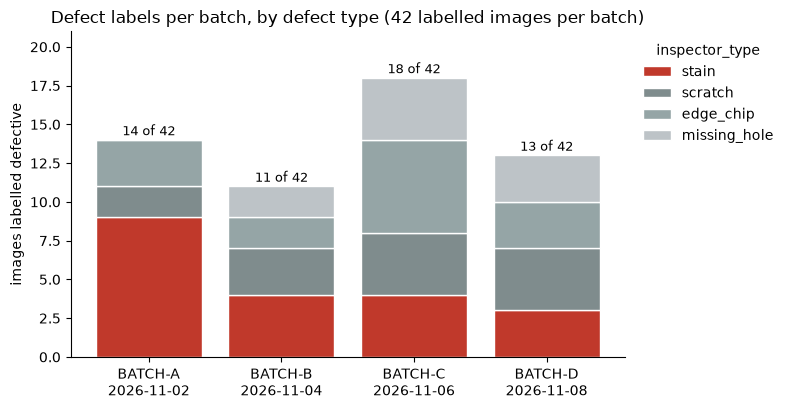

inspector_type,stain,scratch,edge_chip,missing_hole,total
batch,,,,,
BATCH-A,9,2,3,0,14
BATCH-B,4,3,2,2,11
BATCH-C,4,4,6,4,18
BATCH-D,3,4,3,3,13


In [7]:
types = ["stain", "scratch", "edge_chip", "missing_hole"]
ct = pd.crosstab(train.batch, train.inspector_type)[types]
day = train.groupby("batch").timestamp_utc.first().str[:10]

fig, ax = plt.subplots(figsize=(8, 4.2))
bottom = np.zeros(len(ct))
colors = {"stain": "#c0392b", "scratch": "#7f8c8d", "edge_chip": "#95a5a6", "missing_hole": "#bdc3c7"}
for t in types:
    ax.bar(ct.index, ct[t], bottom=bottom, color=colors[t], label=t, edgecolor="white")
    bottom += ct[t].values
for i, (b, tot) in enumerate(zip(ct.index, bottom)):
    ax.text(i, tot + 0.3, f"{int(tot)} of 42", ha="center", fontsize=9)
ax.set_xticks(range(len(ct)), [f"{b}\n{day[b]}" for b in ct.index])
ax.set_ylabel("images labelled defective"); ax.set_ylim(0, bottom.max() + 3)
ax.set_title("Defect labels per batch, by defect type (42 labelled images per batch)")
ax.legend(title="inspector_type", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(ct.assign(total=ct.sum(axis=1)))

**Insight:** scratches, edge chips and missing holes are stable across batches (2–6 each). **Stains** are the outlier:
batch A (Nov 2) has **9 stain labels**, against 3–4 in every other batch.

A sudden spike in a single defect type, on a single day, while the other types stay flat, has two possible explanations:
a real (temporary) stain problem in production, or **labelling drift**, meaning the inspector marked stains more readily that day.
The metadata alone can't tell these apart, but the images can. This is checked in Part B by looking at the batch A stain images
and comparing them with an image-based anomaly score.

## Part B: understanding the images and extracting features

### B1. Six example images (OK and defective)
Two OK images and one example of each defect type. The defect examples were picked by hand because the defect is
clearly visible in them; this is for illustration only and plays no part in any prediction.

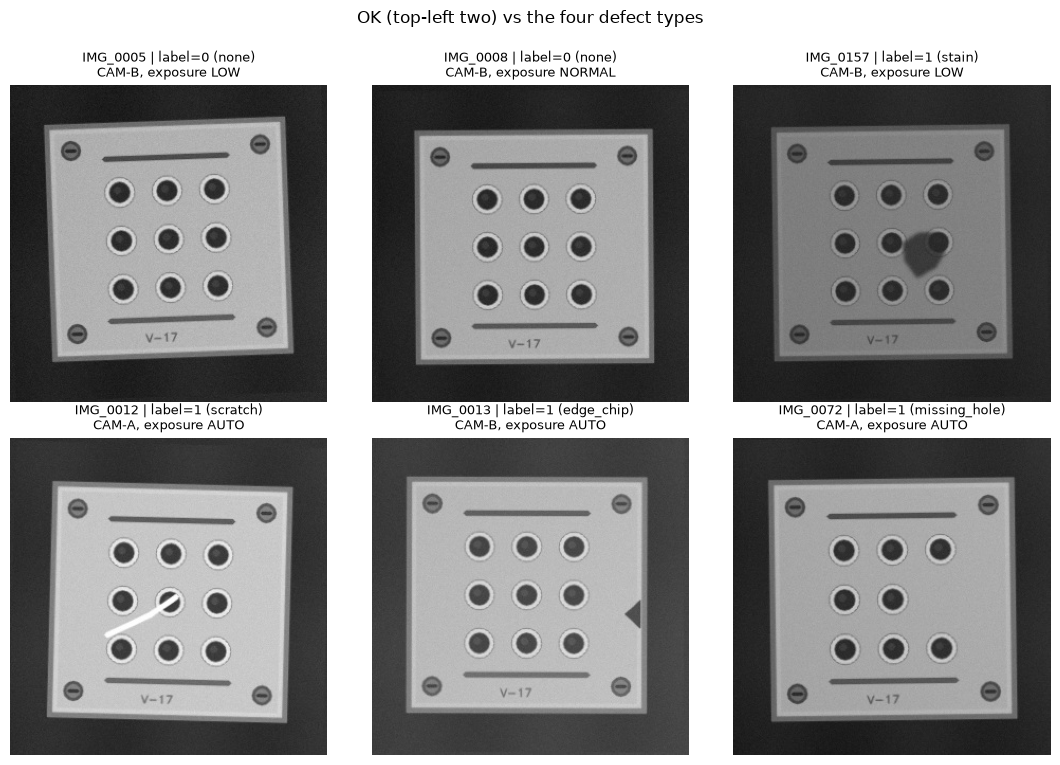

In [8]:
examples = ["IMG_0005", "IMG_0008", "IMG_0157", "IMG_0012", "IMG_0013", "IMG_0072"]
ex = train.set_index("image_id").loc[examples]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.6))
for ax, (iid, r) in zip(axes.flat, ex.iterrows()):
    ax.imshow(read_gray(r.file), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{iid} | label={r.inspector_label} ({r.inspector_type})\n{r.camera}, exposure {r.exposure_setting}", fontsize=9)
    ax.axis("off")
plt.suptitle("OK (top-left two) vs the four defect types", y=1.0); plt.tight_layout(); plt.show()

**Visual differences:**
* Every image shows the same part: a grey square plate on a dark background, with a 3×3 grid of holes, 4 screws, 2 bars and the text "V-17".
  The plate is **slightly rotated and shifted** from image to image, and overall brightness varies with camera and exposure.
* The defects are **small and local**: a dark blob (stain, IMG_0157), a bright line across the holes (scratch, IMG_0012),
  a triangular notch cut into the plate edge (edge chip, IMG_0013) and an empty spot where a hole should be (missing hole, IMG_0072).
  Most of each image is identical between OK and defective parts.

That suggests a feature: whole-image averages (brightness, contrast) should barely react to such a small change, while a
**comparison with what a normal plate looks like** should react strongly. Both ideas are tested below.

### B2. Feature function
Two features:
1. **`anomaly_score`**, the main feature: how far the most unusual region of the plate deviates from a typical OK plate.
   1. Find the plate: Otsu threshold → largest contour → minimum-area rotated rectangle.
   2. Warp the plate to a straight 256×256 square, which removes rotation and shift.
   3. Normalise brightness (subtract the mean, divide by the std), which removes exposure differences.
   4. Smooth lightly (Gaussian, σ=2) so that tiny alignment errors and pixel noise don't count.
   5. Compare with a **template**: the pixel-wise median of OK plates. Score = the largest absolute difference,
      ignoring an 8-pixel border where alignment is least precise.
2. **`sharpness`**: variance of the Laplacian on the raw image. This is a *capture-quality* feature, not a defect feature.
   It's used to check whether blur explains errors (the brief notes that a blurry image is not necessarily a defective part).

`brightness` (mean grey level) is also returned as a reference for capture conditions.

**Avoiding leakage:** the template is built only from OK images in the **development** split. The validation images
(used in Part D) must not influence their own feature, so the 70/30 split is made here and reused in Part C.

In [9]:
from sklearn.model_selection import train_test_split

dev, val = train_test_split(train, test_size=0.30, stratify=train.inspector_label, random_state=SEED)
train["split"] = np.where(train.image_id.isin(dev.image_id), "dev", "val")
print(pd.crosstab(train.split, train.inspector_label, margins=True))

inspector_label    0   1  All
split                        
dev               78  39  117
val               34  17   51
All              112  56  168


In [10]:
SIZE, SIGMA, BORDER = 256, 2.0, 8

def _order_corners(pts):
    # top-left, top-right, bottom-right, bottom-left
    s, d = pts.sum(axis=1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])

def align_plate(gray):
    # Locate the plate and warp it to a straight SIZE x SIZE square.
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))   # fill the dark holes
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    plate = max(contours, key=cv2.contourArea)
    corners = _order_corners(cv2.boxPoints(cv2.minAreaRect(plate)))
    target = np.float32([[0, 0], [SIZE - 1, 0], [SIZE - 1, SIZE - 1], [0, SIZE - 1]])
    return cv2.warpPerspective(gray, cv2.getPerspectiveTransform(corners, target), (SIZE, SIZE)).astype(np.float32)

def normalise(plate):
    z = (plate - plate.mean()) / (plate.std() + 1e-6)
    return cv2.GaussianBlur(z, (0, 0), SIGMA)

def build_template(rel_paths):
    return np.median([normalise(align_plate(read_gray(p))) for p in rel_paths], axis=0)

def anomaly_map(gray, template):
    return np.abs(normalise(align_plate(gray)) - template)

def extract_features(rel_path, template):
    # Read one image and return its numeric features.
    gray = read_gray(rel_path)
    diff = anomaly_map(gray, template)[BORDER:-BORDER, BORDER:-BORDER]
    return {"anomaly_score": float(diff.max()),
            "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            "brightness": float(gray.mean())}

ok_dev = train[(train.split == "dev") & (train.inspector_label == 0)]
TEMPLATE = build_template(ok_dev.file)
print(f"template built from {len(ok_dev)} OK images of the development split")

template built from 78 OK images of the development split


**Sanity check:** does the anomaly map light up on the actual defect? Example images: aligned plate, template, and difference map.

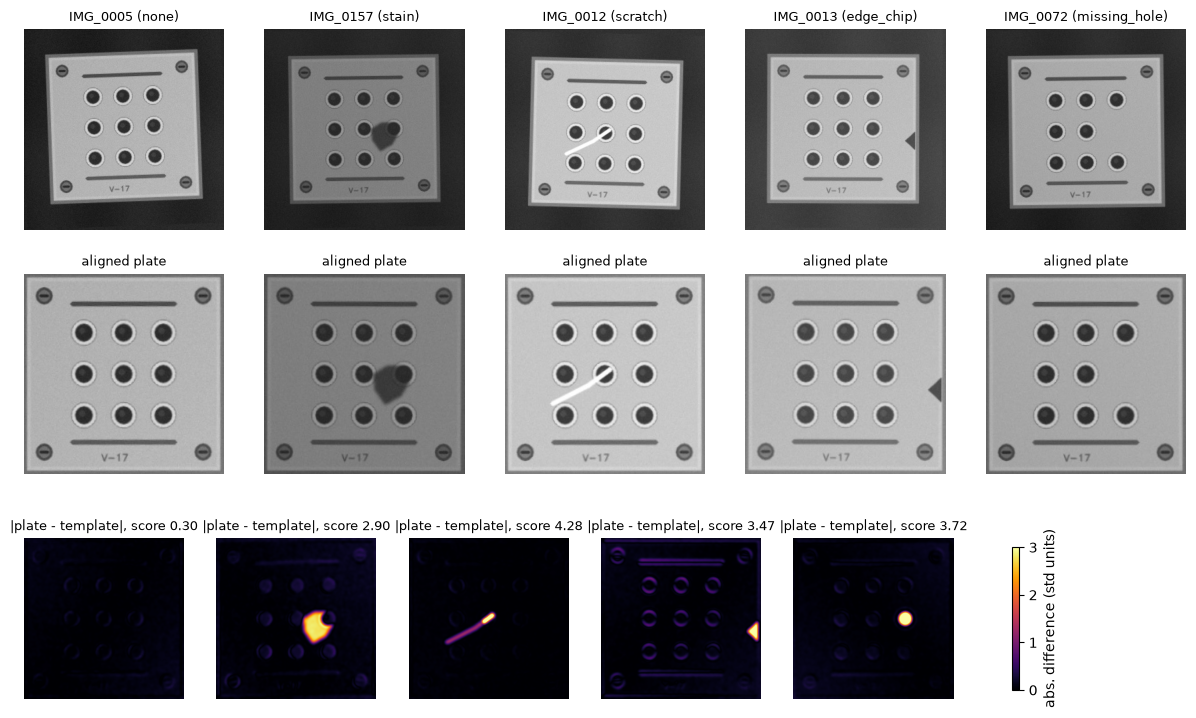

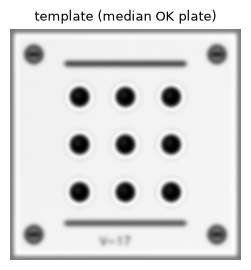

In [11]:
show_ids = ["IMG_0005", "IMG_0157", "IMG_0012", "IMG_0013", "IMG_0072"]
fig, axes = plt.subplots(3, len(show_ids), figsize=(15, 9))
for j, iid in enumerate(show_ids):
    r = train.set_index("image_id").loc[iid]
    g = read_gray(r.file); amap = anomaly_map(g, TEMPLATE)
    axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(f"{iid} ({r.inspector_type})", fontsize=9)
    axes[1, j].imshow(align_plate(g), cmap="gray", vmin=0, vmax=255); axes[1, j].set_title("aligned plate", fontsize=9)
    im = axes[2, j].imshow(amap, cmap="inferno", vmin=0, vmax=3)
    axes[2, j].set_title(f"|plate - template|, score {amap[BORDER:-BORDER, BORDER:-BORDER].max():.2f}", fontsize=9)
for a in axes.flat: a.axis("off")
fig.colorbar(im, ax=axes[2, :], shrink=0.7, label="abs. difference (std units)")
plt.show()

plt.figure(figsize=(3, 3)); plt.imshow(TEMPLATE, cmap="gray"); plt.title("template (median OK plate)", fontsize=9); plt.axis("off"); plt.show()

The difference map is dark for the OK plate and lights up exactly on the stain, the scratch, the chipped edge and the missing hole.
The alignment works well enough that the holes, screws and text cancel out.

### B3. Features for all labelled images, and an OK vs defective comparison

In [12]:
feats = pd.DataFrame([{"image_id": r.image_id, **extract_features(r.file, TEMPLATE)} for r in train.itertuples()])
train = train.drop(columns=[c for c in feats.columns if c != "image_id" and c in train.columns]).merge(feats, on="image_id")
display(train.groupby("inspector_label")[["anomaly_score", "sharpness", "brightness"]].median()
             .rename(index={0: "OK (median)", 1: "defective (median)"}))

,anomaly_score,sharpness,brightness
inspector_label,,,
OK (median),0.406,440.258,114.325
defective (median),3.413,431.713,111.130


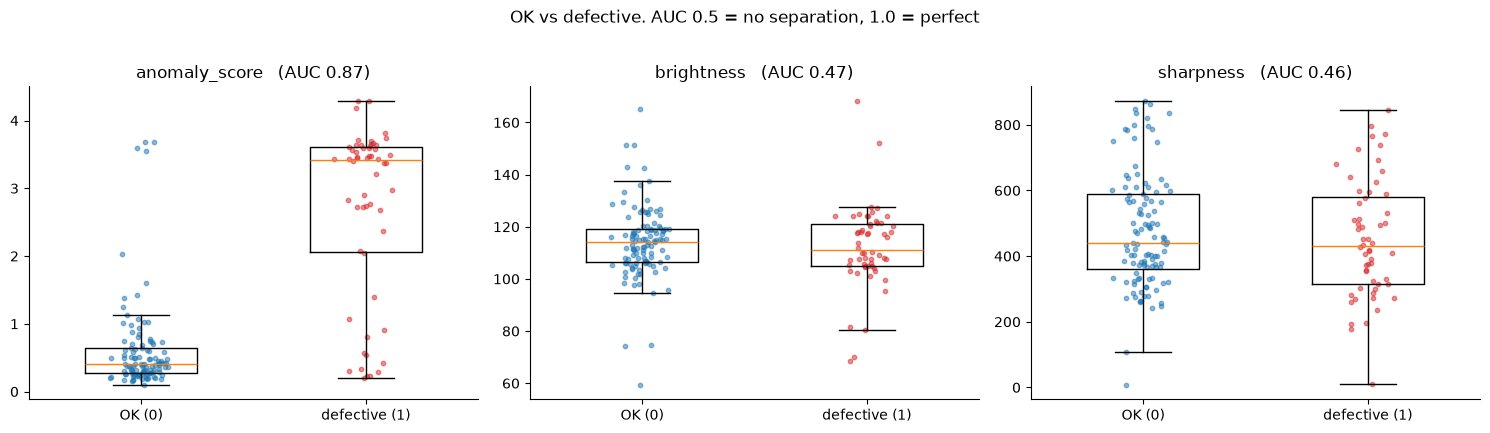

In [13]:
from sklearn.metrics import roc_auc_score

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ["anomaly_score", "brightness", "sharpness"]):
    data = [train.loc[train.inspector_label == k, col] for k in (0, 1)]
    ax.boxplot(data, widths=0.5, showfliers=False)
    for k, d in enumerate(data, start=1):
        ax.scatter(np.random.default_rng(0).normal(k, 0.06, len(d)), d, s=10, alpha=0.5,
                   color="tab:blue" if k == 1 else "tab:red")
    ax.set_xticks([1, 2], ["OK (0)", "defective (1)"])
    auc = roc_auc_score(train.inspector_label, train[col])
    ax.set_title(f"{col}   (AUC {auc:.2f})")
plt.suptitle("OK vs defective. AUC 0.5 = no separation, 1.0 = perfect", y=1.02); plt.tight_layout(); plt.show()

**Comparison:** `anomaly_score` separates the groups clearly (AUC ≈ 0.87): defective parts have a much higher median score.
Brightness and sharpness don't separate them at all (AUC ≈ 0.5), as expected: a defect changes a small area, while
whole-image statistics are dominated by capture conditions. *(These AUCs use all 168 labelled images; the template saw only
the development OK images. The honest held-out evaluation is in Part D.)*

Two groups don't fit the pattern: some **defective-labelled images with a low score**, and a few **OK-labelled images with a high score**.
Looking at them by defect type:

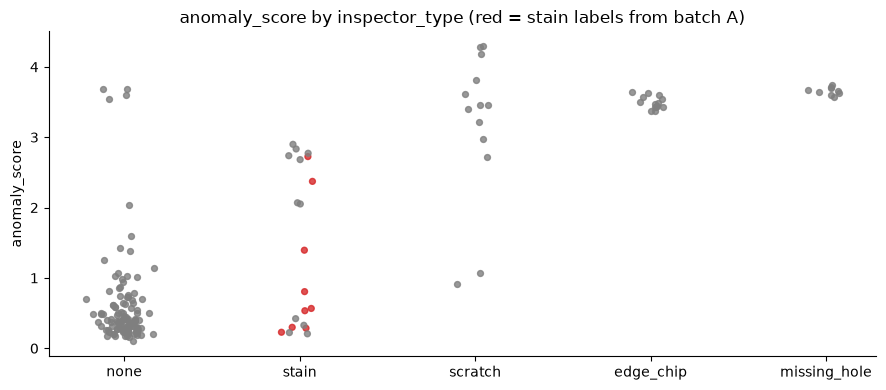

90th percentile of OK scores: 1.03  (a stain label scoring below it looks like an ordinary OK plate)


,stain_labels,scores_like_OK,stain_visible_in_image
batch,,,
BATCH-A,9,6,3
BATCH-B,4,3,1
BATCH-C,4,0,4
BATCH-D,3,1,2


In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
order = ["none", "stain", "scratch", "edge_chip", "missing_hole"]
for k, t in enumerate(order):
    s = train[train.inspector_type == t]
    pt_colors = np.where(s.batch == "BATCH-A", "tab:red", "tab:gray") if t == "stain" else "tab:gray"
    ax.scatter(np.random.default_rng(1).normal(k, 0.08, len(s)), s.anomaly_score, s=18, c=pt_colors, alpha=0.8)
ax.set_xticks(range(len(order)), order); ax.set_ylabel("anomaly_score")
ax.set_title("anomaly_score by inspector_type (red = stain labels from batch A)")
plt.tight_layout(); plt.show()

ok_max = train.loc[train.inspector_type == "none", "anomaly_score"].quantile(0.90)
st = train[train.inspector_type == "stain"].assign(visible=lambda d: d.anomaly_score >= ok_max)
print(f"90th percentile of OK scores: {ok_max:.2f}  (a stain label scoring below it looks like an ordinary OK plate)")
display(st.groupby("batch").agg(stain_labels=("image_id", "size"),
                                scores_like_OK=("visible", lambda v: int((~v).sum())),
                                stain_visible_in_image=("visible", "sum")))

Scratches, edge chips and missing holes almost always score high. **Stains split into two groups:** about half score
clearly high, and the other half score like OK plates. If only the stain labels with a clear image signal are counted,
batch A has about as many as the other batches, so **the batch A stain spike from Part A disappears**.
Here are the lowest-scoring stain labels next to the highest-scoring ones:

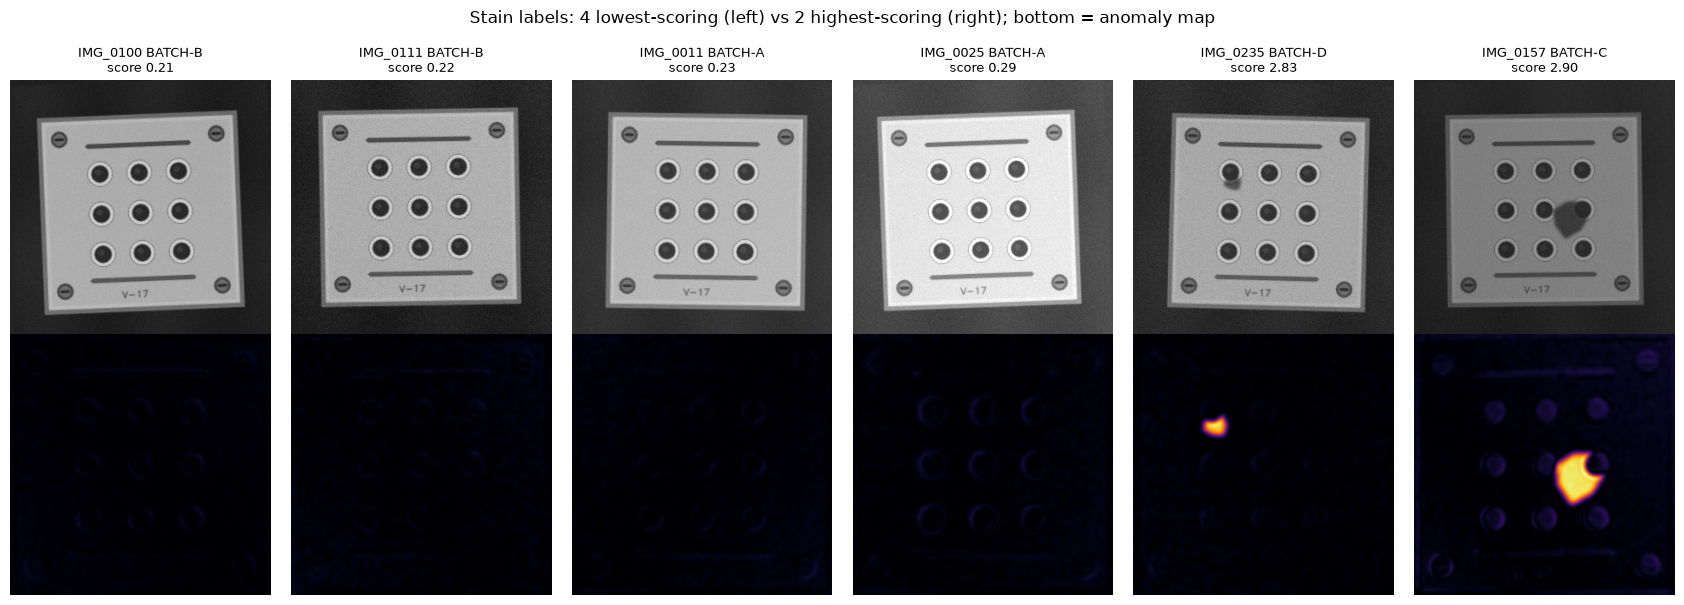

In [15]:
st_sorted = train[train.inspector_type == "stain"].sort_values("anomaly_score")
pick = pd.concat([st_sorted.head(4), st_sorted.tail(2)])
fig, axes = plt.subplots(2, 6, figsize=(17, 6))
for j, r in enumerate(pick.itertuples()):
    g = read_gray(r.file)
    axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"{r.image_id} {r.batch}\nscore {r.anomaly_score:.2f}", fontsize=9)
    axes[1, j].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
for a in axes.flat: a.axis("off")
plt.suptitle("Stain labels: 4 lowest-scoring (left) vs 2 highest-scoring (right); bottom = anomaly map", y=1.0)
plt.tight_layout(); plt.show()

**Follow-up on the Part A insight:** the low-scoring stain labels show **no visible stain**, either in the image or in the anomaly map,
while the high-scoring ones have an obvious dark blob. So a large part of batch A's stain spike most likely comes from the
**labels, not the parts**: the inspector seems to have over-marked stains on that day (or the stains are too faint to see in these images).
This can't be proven without re-inspecting the physical parts, but it matters for everything below:
**the training labels contain noise**, and a model can't be expected to "find" stains that aren't visible.

The noise goes the other way too. A few images labelled **OK** score as high as clear defects:

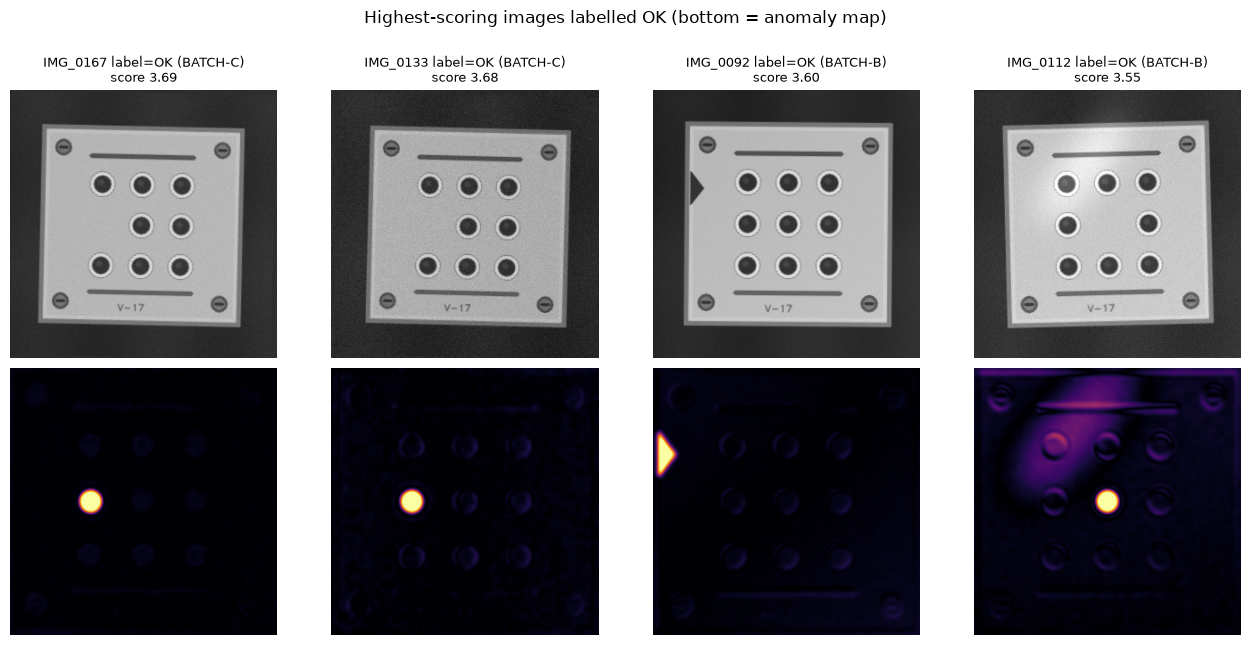

In [16]:
ok_high = train[train.inspector_label == 0].nlargest(4, "anomaly_score")
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
for j, r in enumerate(ok_high.itertuples()):
    g = read_gray(r.file)
    axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"{r.image_id} label=OK ({r.batch})\nscore {r.anomaly_score:.2f}", fontsize=9)
    axes[1, j].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
for a in axes.flat: a.axis("off")
plt.suptitle("Highest-scoring images labelled OK (bottom = anomaly map)", y=1.0); plt.tight_layout(); plt.show()

These are **clear defects that the inspector labelled OK**: three plates are missing a hole (IMG_0167, 0133, 0112) and one has
an edge chip (IMG_0092). IMG_0112 also has a bright **glare spot** in the top-left, a lighting artifact that the anomaly map
picks up weakly, so capture conditions can add to the score too.

**Conclusion of Part B:** the labels are noisy in **both directions**: invisible "stains" labelled defective, and visible defects labelled OK.
Any validation metric computed against these labels will therefore *understate* how well an image-based detector really works.
When such images land in validation, they'll count as model errors even where the model is right.

### B4. Label verification: collecting the mismatches and reviewing them by hand

Steps:
1. Collect every labelled image where `anomaly_score` and the label strongly disagree.
2. Review each one by eye: **real defect**, **label error**, or **photo artifact**?
3. Store the result in new columns, `verified_label` and `verified_type` (the corrected defect type), plus the verdict
   and a comment. The original `inspector_label` / `inspector_type` are kept unchanged, and everything is saved to `train_verified.csv`.
4. Recompute ROC-AUC on the verified labels and compare it with the original labels.

**Mismatch rule:** the threshold is the 90th percentile of OK-labelled scores (≈1.03, from B3).
* labelled **defective** but score **below** the threshold (it looks like an OK plate), or
* labelled **OK** but score **at or above** the threshold.

Only `train.csv` images are reviewed. Test images are never labelled by hand (the brief forbids it).

threshold = 1.03   mismatches: 23 of 168 labelled images (11 labelled defective with a low score, 12 labelled OK with a high score)


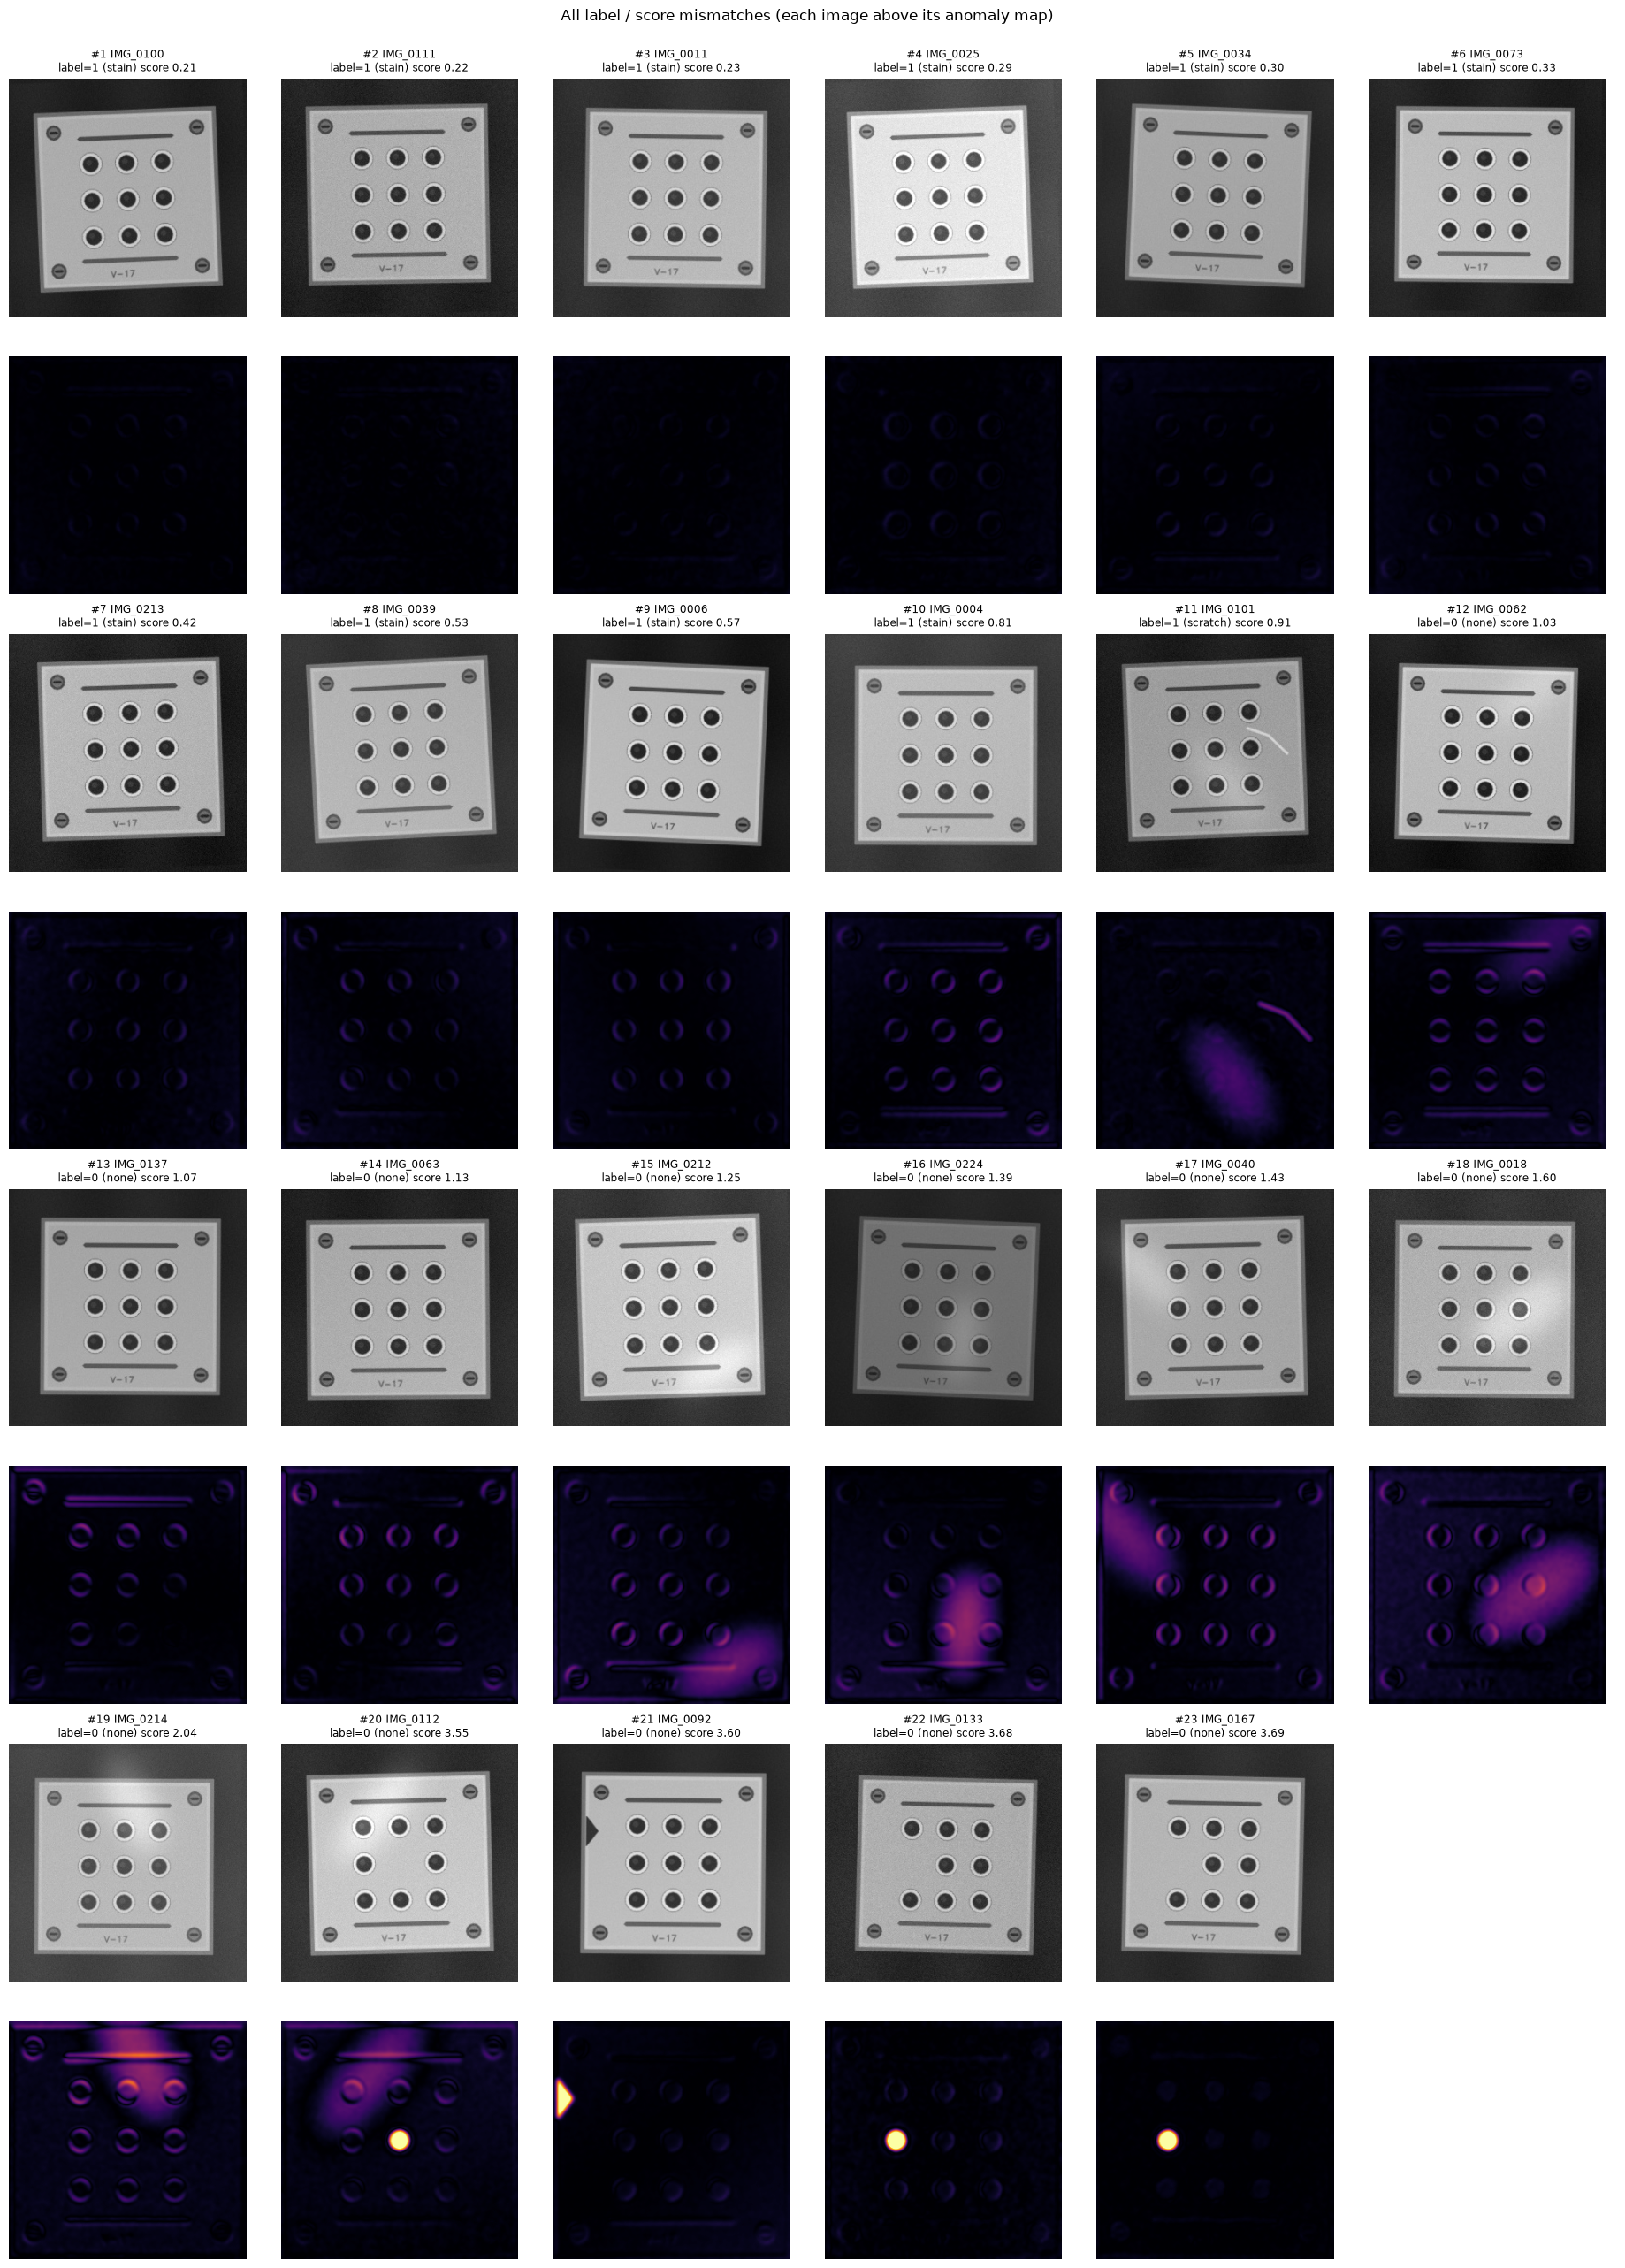

In [17]:
THR = train.loc[train.inspector_label == 0, "anomaly_score"].quantile(0.90)
mism = train[((train.inspector_label == 1) & (train.anomaly_score < THR)) |
             ((train.inspector_label == 0) & (train.anomaly_score >= THR))].copy()
mism = mism.sort_values(["inspector_label", "anomaly_score"], ascending=[False, True]).reset_index(drop=True)
print(f"threshold = {THR:.2f}   mismatches: {len(mism)} of {len(train)} labelled images "
      f"({(mism.inspector_label == 1).sum()} labelled defective with a low score, "
      f"{(mism.inspector_label == 0).sum()} labelled OK with a high score)")

per_row = 6
n_rows = int(np.ceil(len(mism) / per_row))
fig, axes = plt.subplots(2 * n_rows, per_row, figsize=(3.1 * per_row, 6.4 * n_rows))
for a in axes.flat: a.axis("off")
for k, r in enumerate(mism.itertuples()):
    row, col = 2 * (k // per_row), k % per_row
    g = read_gray(r.file)
    axes[row, col].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[row, col].set_title(f"#{k+1} {r.image_id}\nlabel={r.inspector_label} ({r.inspector_type}) score {r.anomaly_score:.2f}", fontsize=8.5)
    axes[row + 1, col].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
plt.suptitle("All label / score mismatches (each image above its anomaly map)", y=1.0)
plt.tight_layout(); plt.show()

**Review result** (each image was inspected by eye at full size, together with its anomaly map):

| group | images | label | what is visible | verdict | `verified_label` |
|---|---|---|---|---|---|
| invisible "stains" | IMG_0100, 0111, 0011, 0025, 0034, 0073, 0213, 0039, 0006, 0004 | 1 | no stain in the image, flat anomaly map | **label error** | 0 |
| thin scratch | IMG_0101 | 1 | a real short, thin scratch (plus a glare patch) | **real defect** (a model miss) | 1 |
| missed defects | IMG_0167, 0133, 0112 (missing hole), IMG_0092 (edge chip) | 0 | the defect is clearly visible | **label error** | 1 |
| glare / lighting | IMG_0214, 0018, 0040, 0224, 0212, 0063, 0137, 0062 | 0 | bright glare or lighting spots; the part itself looks fine | **photo artifact** (a model weakness) | 0 |

Caveat for the invisible stains: a very faint stain might fall below what this camera captures (e.g. IMG_0025 is overexposed).
"Not visible in the image" is the best judgement available from the data, not a physical re-inspection.

In [18]:
# image_id -> (verdict, verified_label, verified_type, comment)
REVIEW = {
    **{i: ("label_error", 0, "none", "labelled stain, but no stain visible; flat anomaly map")
       for i in ["IMG_0100", "IMG_0111", "IMG_0011", "IMG_0025", "IMG_0034",
                 "IMG_0073", "IMG_0213", "IMG_0039", "IMG_0006", "IMG_0004"]},
    "IMG_0101": ("real_defect", 1, "scratch", "real thin scratch; low score is a model miss"),
    **{i: ("label_error", 1, "missing_hole", "labelled OK, but a hole is clearly missing")
       for i in ["IMG_0167", "IMG_0133", "IMG_0112"]},
    "IMG_0092": ("label_error", 1, "edge_chip", "labelled OK, but the plate edge is clearly chipped"),
    **{i: ("photo_artifact", 0, "none", "glare / lighting spot raises the score; part looks fine")
       for i in ["IMG_0214", "IMG_0018", "IMG_0040", "IMG_0224",
                 "IMG_0212", "IMG_0063", "IMG_0137", "IMG_0062"]},
}
assert set(REVIEW) == set(mism.image_id), "every mismatch must have a review decision (and nothing else)"

# New columns: the original inspector_label / inspector_type are kept unchanged.
rv = lambda i, k, default: REVIEW[i][k] if i in REVIEW else default
train["review"] = [rv(i, 0, "not_reviewed") for i in train.image_id]
train["verified_label"] = [rv(i, 1, lab) for i, lab in zip(train.image_id, train.inspector_label)]
train["verified_type"] = [rv(i, 2, t) for i, t in zip(train.image_id, train.inspector_type)]
train["review_comment"] = [rv(i, 3, "") for i in train.image_id]
train["label_changed"] = train.verified_label != train.inspector_label

print("All reviewed images: original vs corrected")
cols = ["image_id", "batch", "split", "anomaly_score", "inspector_label", "inspector_type",
        "verified_label", "verified_type", "review", "review_comment"]
reviewed = train[train.review != "not_reviewed"].sort_values(["review", "image_id"])[cols]
display(reviewed.style.format({"anomaly_score": "{:.2f}"})
        .apply(lambda r: ["background-color:#fde2c8" if train.set_index("image_id").loc[r.image_id, "label_changed"] else ""] * len(r), axis=1)
        .hide(axis="index"))

All reviewed images: original vs corrected


image_id,batch,split,anomaly_score,inspector_label,inspector_type,verified_label,verified_type,review,review_comment
IMG_0004,BATCH-A,dev,0.81,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0006,BATCH-A,dev,0.57,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0011,BATCH-A,dev,0.23,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0025,BATCH-A,val,0.29,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0034,BATCH-A,dev,0.30,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0039,BATCH-A,val,0.53,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0073,BATCH-B,dev,0.33,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0092,BATCH-B,dev,3.60,0,none,1,edge_chip,label_error,"labelled OK, but the plate edge is clearly chipped"
IMG_0100,BATCH-B,dev,0.21,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0111,BATCH-B,val,0.22,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"


In [19]:
display(pd.crosstab(train.inspector_label, train.verified_label, rownames=["inspector_label"], colnames=["verified_label"], margins=True))
display(pd.crosstab(train.inspector_type, train.verified_type, rownames=["inspector_type"], colnames=["verified_type"], margins=True))
print("changed labels by split:", train[train.label_changed].split.value_counts().to_dict())

# Save the corrected labels next to the original data (train.csv itself is not modified).
out_cols = list(pd.read_csv(DATA_DIR / "train.csv").columns) + ["verified_label", "verified_type", "review", "review_comment"]
train[out_cols].sort_values("image_id").to_csv(DATA_DIR / "train_verified.csv", index=False)
print(f"saved train_verified.csv: {len(train)} rows, {int(train.label_changed.sum())} labels corrected")

verified_label,0,1,All
inspector_label,,,
0,108,4,112
1,10,46,56
All,118,50,168


verified_type,edge_chip,missing_hole,none,scratch,stain,All
inspector_type,,,,,,
edge_chip,14,0,0,0,0,14
missing_hole,0,9,0,0,0,9
none,1,3,108,0,0,112
scratch,0,0,0,13,0,13
stain,0,0,10,0,10,20
All,15,12,118,13,10,168


changed labels by split: {'dev': 11, 'val': 3}
saved train_verified.csv: 168 rows, 14 labels corrected


,AUC vs inspector_label,AUC vs verified_label
set,,
all labelled (168),0.868,0.996
validation split only (51),0.877,1.000


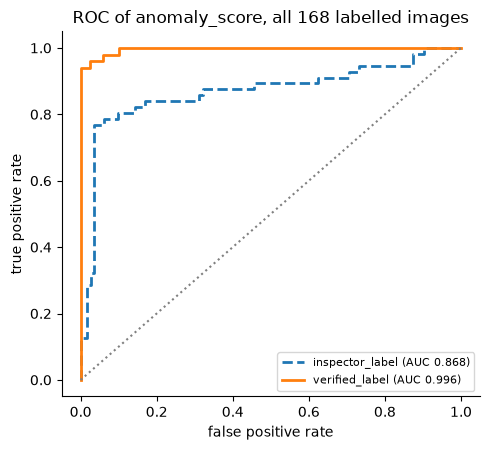

In [20]:
from sklearn.metrics import roc_curve

def auc_table(df):
    rows = []
    for name, sub in [("all labelled (168)", df), ("validation split only (51)", df[df.split == "val"])]:
        rows.append({"set": name,
                     "AUC vs inspector_label": roc_auc_score(sub.inspector_label, sub.anomaly_score),
                     "AUC vs verified_label": roc_auc_score(sub.verified_label, sub.anomaly_score)})
    return pd.DataFrame(rows).set_index("set")

auc_before_after = auc_table(train)
display(auc_before_after.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(5, 4.6))
for col, ls in [("inspector_label", "--"), ("verified_label", "-")]:
    fpr, tpr, _ = roc_curve(train[col], train.anomaly_score)
    ax.plot(fpr, tpr, ls, lw=2, label=f"{col} (AUC {roc_auc_score(train[col], train.anomaly_score):.3f})")
ax.plot([0, 1], [0, 1], ":", color="gray")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC of anomaly_score, all 168 labelled images"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Before vs after label correction:** with the verified labels, the anomaly score is close to a perfect ranking. Most of the
"errors" against the original labels were **label errors, not model errors**: 14 of 168 labels (8 %) changed.
The remaining disagreements are real model weaknesses: a thin scratch that scores low, and glare spots that score high.

**Read this improvement with care. It is optimistic by construction:** only images where the model disagreed with the label
were reviewed, so any change can only move the label *toward* the model. Images the model and the inspector got wrong *together*
(e.g. a faint defect both missed) were never looked at. The real performance lies somewhere between the two numbers.
A fair estimate would need a random sample reviewed blind, without looking at the score.

**How the verified labels are used next:** Part C trains on `verified_label`, because training on known-wrong labels would teach
the model that a missing hole is OK. Part D reports validation metrics against **both** label sets, so the effect stays visible.
(The template still includes the 4 missed defects among its 78 "OK" plates. The pixel-wise median is robust to a few outliers,
so they don't distort it.)

### B5. Recalculating Parts A and B on the corrected labels
Every analysis from Parts A and B is repeated with `verified_label` / `verified_type`, next to the original result,
to see which conclusions change.

In [21]:
LABELS = {"inspector_label": "original", "verified_label": "verified"}

print("Label distribution")
display(pd.DataFrame({name: train[col].value_counts().rename({0: "OK (0)", 1: "defective (1)"})
                      for col, name in LABELS.items()})
          .assign(change=lambda d: d.verified - d.original)
          .pipe(lambda d: pd.concat([d, (100 * d[["original", "verified"]] / len(train)).round(1).add_suffix("_%")], axis=1)))

Label distribution


,original,verified,change,original_%,verified_%
OK (0),112,118,6,66.7,70.2
defective (1),56,50,-6,33.3,29.8


In [22]:
def rate_table(field):
    g = train.groupby(field)
    out = pd.DataFrame({"n": g.size()})
    for col, name in LABELS.items():
        out[f"{name}_defect_%"] = (100 * g[col].mean()).round(1)
    out["change_pts"] = out["verified_defect_%"] - out["original_defect_%"]
    return out

print("Defect rate per camera: original vs verified")
cam_tab = rate_table("camera")
for cam, r in cam_tab.iterrows():
    p = r["verified_defect_%"] / 100
    cam_tab.loc[cam, "verified_95%CI_±pts"] = round(196 * np.sqrt(p * (1 - p) / r.n), 1)
display(cam_tab)

print("All metadata fields: original vs verified")
display(pd.concat({f: rate_table(f) for f in ["camera", "line", "shift", "exposure_setting", "batch"]}))

Defect rate per camera: original vs verified


,n,original_defect_%,verified_defect_%,change_pts,verified_95%CI_±pts
camera,,,,,
CAM-A,95,31.6,26.3,-5.3,8.9
CAM-B,73,35.6,34.2,-1.4,10.9


All metadata fields: original vs verified


n  original_defect_%  verified_defect_%  change_pts
camera           CAM-A    95               31.6               26.3        -5.3
                 CAM-B    73               35.6               34.2        -1.4
line             LINE-1   88               33.0               27.3        -5.7
                 LINE-2   80               33.8               32.5        -1.3
shift            DAY      82               31.7               30.5        -1.2
                 NIGHT    86               34.9               29.1        -5.8
exposure_setting AUTO     80               30.0               30.0         0.0
                 LOW      48               37.5               35.4        -2.1
                 NORMAL   40               35.0               22.5       -12.5
batch            BATCH-A  42               33.3               19.0       -14.3
                 BATCH-B  42               26.2               23.8        -2.4
                 BATCH-C  42               42.9               47.6         4.7
                 BATCH-D  42               31.0               28.6        -2.4

In [23]:
from scipy.stats import fisher_exact

def fisher(mask, label="verified_label"):
    # 2x2 Fisher exact test: defect rate inside `mask` vs everywhere else.
    a, b = train.loc[mask, label].sum(), (~train.loc[mask, label].astype(bool)).sum()
    c, d = train.loc[~mask, label].sum(), (~train.loc[~mask, label].astype(bool)).sum()
    return fisher_exact([[a, b], [c, d]])[1]

tests = []
for name, mask in [("CAM-B vs CAM-A", train.camera == "CAM-B"),
                   ("BATCH-C vs other batches", train.batch == "BATCH-C"),
                   ("BATCH-A vs other batches", train.batch == "BATCH-A")]:
    tests.append({"comparison": name,
                  "p (original labels)": fisher(mask, "inspector_label"),
                  "p (verified labels)": fisher(mask, "verified_label")})
display(pd.DataFrame(tests).set_index("comparison").style.format("{:.3f}"))
print("p < 0.05 is conventionally 'unlikely to be chance'. Several comparisons are tested, so treat p near 0.05 with care.")

,p (original labels),p (verified labels)
comparison,,
CAM-B vs CAM-A,0.622,0.308
BATCH-C vs other batches,0.136,0.006
BATCH-A vs other batches,1.000,0.084


p < 0.05 is conventionally 'unlikely to be chance'. Several comparisons are tested, so treat p near 0.05 with care.


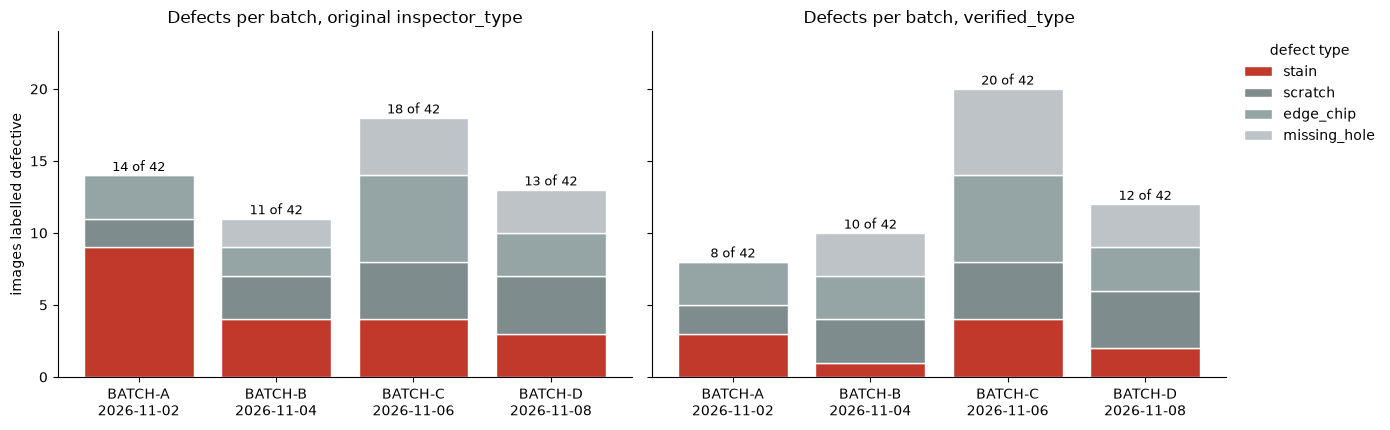

Defect type per batch (verified):


verified_type,stain,scratch,edge_chip,missing_hole,total
batch,,,,,
BATCH-A,3,2,3,0,8
BATCH-B,1,3,3,3,10
BATCH-C,4,4,6,6,20
BATCH-D,2,4,3,3,12


Defect type per camera (verified):


verified_type,stain,scratch,edge_chip,missing_hole,total
camera,,,,,
CAM-A,5,7,5,8,25
CAM-B,5,6,10,4,25


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, (tcol, title) in zip(axes, [("inspector_type", "original inspector_type"), ("verified_type", "verified_type")]):
    ct = pd.crosstab(train.batch, train[tcol]).reindex(columns=types, fill_value=0)
    bottom = np.zeros(len(ct))
    for t in types:
        ax.bar(ct.index, ct[t], bottom=bottom, color=colors[t], label=t, edgecolor="white")
        bottom += ct[t].values
    for i, tot in enumerate(bottom):
        ax.text(i, tot + 0.3, f"{int(tot)} of 42", ha="center", fontsize=9)
    ax.set_xticks(range(len(ct)), [f"{b}\n{day[b]}" for b in ct.index])
    ax.set_title(f"Defects per batch, {title}")
axes[0].set_ylabel("images labelled defective"); axes[0].set_ylim(0, 24)
axes[1].legend(title="defect type", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

print("Defect type per batch (verified):")
display(pd.crosstab(train.batch, train.verified_type)[types].assign(total=lambda d: d.sum(axis=1)))
print("Defect type per camera (verified):")
display(pd.crosstab(train.camera, train.verified_type)[types].assign(total=lambda d: d.sum(axis=1)))

,AUC vs original,AUC vs verified
feature,,
anomaly_score,0.868,0.996
brightness,0.472,0.489
sharpness,0.463,0.465


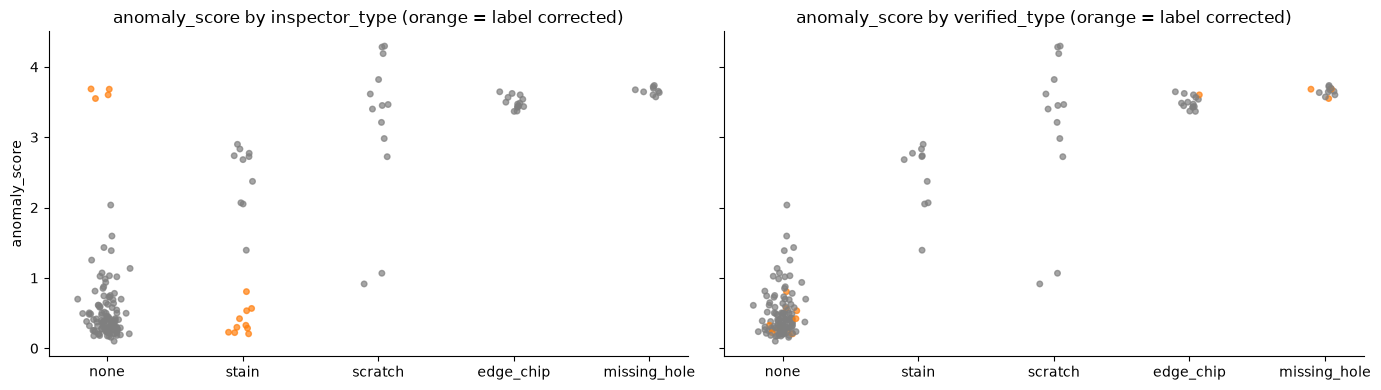

In [25]:
rows = []
for col in ["anomaly_score", "brightness", "sharpness"]:
    rows.append({"feature": col, **{f"AUC vs {name}": roc_auc_score(train[lab], train[col]) for lab, name in LABELS.items()}})
display(pd.DataFrame(rows).set_index("feature").style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
order = ["none", "stain", "scratch", "edge_chip", "missing_hole"]
for ax, tcol in zip(axes, ["inspector_type", "verified_type"]):
    for k, t in enumerate(order):
        s = train[train[tcol] == t]
        ax.scatter(np.random.default_rng(1).normal(k, 0.08, len(s)), s.anomaly_score, s=16, alpha=0.7,
                   c=np.where(s.label_changed, "tab:orange", "tab:gray"))
    ax.set_xticks(range(len(order)), order); ax.set_title(f"anomaly_score by {tcol} (orange = label corrected)")
axes[0].set_ylabel("anomaly_score")
plt.tight_layout(); plt.show()

**What changes with the corrected labels:**

| question | original labels | verified labels |
|---|---|---|
| overall defect rate | 33.3 % (56) | **29.8 %** (50) |
| batch A (Nov 2) | 33.3 %, with a stain spike (9 stains) | **19.0 %, the lowest batch**; 3 stains, in line with the others |
| batch C (Nov 6) | 42.9 %, the highest, but not significant (p = 0.14) | **47.6 %, the highest and significant (p = 0.006)**: 6 edge chips + 6 missing holes, against 0–3 elsewhere |
| camera | 31.6 % vs 35.6 % (p = 0.62) | 26.3 % vs 34.2 % (p = 0.31): the gap widens but is still not significant |
| anomaly_score AUC | 0.868 | 0.996 |
| brightness / sharpness AUC | ≈ 0.5 | ≈ 0.5: still useless as defect features |

**Conclusions:**
1. **The Part A insight flips.** Batch A's apparent stain problem was a labelling problem. With verified labels it is the
   *cleanest* batch (19 %), although that low rate on its own is not significant (p = 0.08).
2. **The real quality signal is batch C, and the label noise was hiding it.** With the original labels, batch C's excess looked like
   chance (p = 0.14), because the invisible batch A/B "stains" inflated the other batches and the missed defects deflated batch C.
   After correction it is clear (p = 0.006, still significant after a Bonferroni correction for the 3 tests: 0.05/3 ≈ 0.017).
   The excess comes from structural defects (edge chips, missing holes) that are clearly visible in the images, so it is not a
   labelling artifact. This is where production should look first (what was different on Nov 6?).
3. **Camera:** CAM-B's rate is higher, and it has 10 of the 15 edge chips, but the difference is not statistically clear (p = 0.31).
   CAM-B is also the only camera with LOW exposure, so "camera" and "exposure" can't be separated with this data.
   This is worth monitoring, not concluding.
4. **The alerts are explained by a mix of things:** a real quality issue (batch C) plus labelling noise in both directions,
   not by capture conditions, since brightness and sharpness carry no defect signal.

## Part C: a first-pass detector

### Model choice
**Logistic regression on a single feature, `anomaly_score`.**
* Part B showed that `anomaly_score` carries almost all the signal (AUC 0.996 on verified labels), while brightness and
  sharpness carry none (AUC ≈ 0.5). Adding them would only add noise and make the model harder to explain.
* With one feature, logistic regression is just a **threshold on the anomaly score** ("flag a part if its most unusual region deviates
  more than X from a normal plate"), and it also produces a 0–1 `score`, as the output format requires.
* Sharpness is kept out of the model on purpose: the brief notes that blurry ≠ defective. It is used for error analysis instead.

### Training setup
* **Labels:** `verified_label` (Part B4). Training on known-wrong labels (e.g. a missing hole labelled OK) would teach the wrong boundary.
* **Split:** the stratified 70/30 dev/validation split from Part B (117 / 51). The model and threshold are fit on **dev only**,
  and validation is used only for evaluation in Part D. `test.csv` is never used to fit or tune anything.
* **Threshold:** the default probability cut of 0.5. Part D compares it with a second threshold.

In [26]:
from sklearn.linear_model import LogisticRegression

FEATURES = ["anomaly_score"]
TARGET = "verified_label"
dev, val = train[train.split == "dev"], train[train.split == "val"]

model = LogisticRegression().fit(dev[FEATURES], dev[TARGET])
THRESHOLD = 0.5
cut = -model.intercept_[0] / model.coef_[0, 0]
print(f"fitted on {len(dev)} dev images:  P(defect) = sigmoid({model.coef_[0,0]:.2f} * anomaly_score {model.intercept_[0]:+.2f})")
print(f"=> decision rule: flag as defective if anomaly_score >= {cut:.2f}  (P >= {THRESHOLD})")

train["score_dev_model"] = model.predict_proba(train[FEATURES])[:, 1]
train["pred_dev_model"] = (train.score_dev_model >= THRESHOLD).astype(int)

fitted on 117 dev images:  P(defect) = sigmoid(2.57 * anomaly_score -4.65)
=> decision rule: flag as defective if anomaly_score >= 1.81  (P >= 0.5)


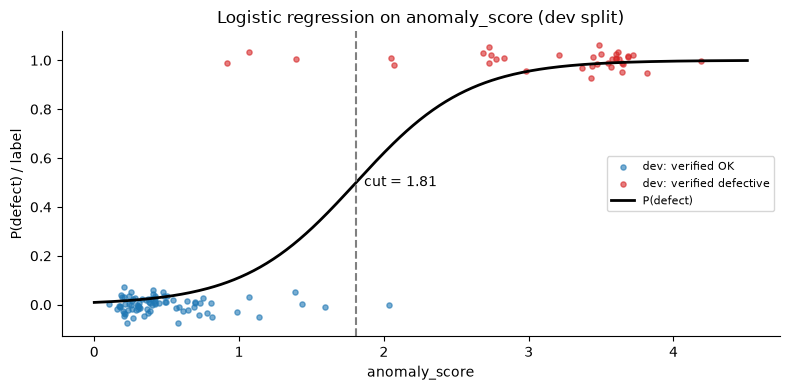

In [27]:
xs = np.linspace(0, train.anomaly_score.max() * 1.05, 300)
fig, ax = plt.subplots(figsize=(8, 4))
for lab, c, name in [(0, "tab:blue", "verified OK"), (1, "tab:red", "verified defective")]:
    s = dev[dev[TARGET] == lab]
    ax.scatter(s.anomaly_score, np.random.default_rng(2).normal(lab, 0.03, len(s)), s=14, alpha=0.6, color=c, label=f"dev: {name}")
ax.plot(xs, model.predict_proba(pd.DataFrame({"anomaly_score": xs}))[:, 1], color="k", lw=2, label="P(defect)")
ax.axvline(cut, ls="--", color="gray"); ax.text(cut, 0.5, f"  cut = {cut:.2f}", va="center")
ax.set_xlabel("anomaly_score"); ax.set_ylabel("P(defect) / label"); ax.legend(fontsize=8, loc="center right")
ax.set_title("Logistic regression on anomaly_score (dev split)")
plt.tight_layout(); plt.show()

### Final model and predictions for `test.csv`
For the submission, the model is **refit on all 168 labelled images** (dev + validation), with the same feature, labels and threshold.
More data gives a slightly more stable cut, and the configuration itself was fixed before looking at validation.
The template stays the one built from dev OK images, so test features are computed exactly as the validated features were.

In [28]:
test_feats = pd.DataFrame([{"image_id": r.image_id, **extract_features(r.file, TEMPLATE)} for r in test.itertuples()])
test = test.drop(columns=[c for c in test_feats.columns if c != "image_id" and c in test.columns]).merge(test_feats, on="image_id")

final_model = LogisticRegression().fit(train[FEATURES], train[TARGET])
final_cut = -final_model.intercept_[0] / final_model.coef_[0, 0]
test["score"] = final_model.predict_proba(test[FEATURES])[:, 1]
test["predicted_defect"] = (test.score >= THRESHOLD).astype(int)
print(f"final model (168 images): flag if anomaly_score >= {final_cut:.2f}")

predictions = test[["image_id", "predicted_defect", "score"]].copy()
predictions["score"] = predictions.score.round(4)

# --- validate the output format before saving ---
assert len(predictions) == 72 and predictions.image_id.tolist() == pd.read_csv(DATA_DIR / "test.csv").image_id.tolist()
assert predictions.predicted_defect.isin([0, 1]).all() and predictions.score.between(0, 1).all()
assert not predictions.isna().any().any() and predictions.image_id.is_unique
assert list(predictions.columns) == list(pd.read_csv(DATA_DIR / "sample_predictions.csv").columns)
predictions.to_csv(DATA_DIR / "predictions.csv", index=False)

print(f"saved predictions.csv: {len(predictions)} rows; predicted defective: {predictions.predicted_defect.sum()} "
      f"({100 * predictions.predicted_defect.mean():.1f} %), train verified defect rate: {100 * train[TARGET].mean():.1f} %")
display(predictions.head())

final model (168 images): flag if anomaly_score >= 1.84


saved predictions.csv: 72 rows; predicted defective: 20 (27.8 %), train verified defect rate: 29.8 %


,image_id,predicted_defect,score
0,IMG_0001,0,0.411
1,IMG_0002,0,0.016
2,IMG_0003,0,0.016
3,IMG_0010,0,0.011
4,IMG_0014,1,0.996


### Sanity checks on the test predictions
* Is the share of predicted defects plausible compared with the training data?
* Capture conditions: the test set contains **7 extremely blurry CAM-B images** (sharpness < 20). Train has only **2** images that blurry
  out of 168. A model can't be trusted on inputs it hardly saw in training, so every image with low sharpness (< 150, which also catches
  very dark, low-contrast images) is flagged as **uncertain**, together with any image whose score falls in the grey zone (0.2–0.8).

sharpness < 20: train 2 of 168, test 7 of 72
sharpness < 150: train 3 of 168, test 8 of 72
test images flagged uncertain: 13


image_id,camera,exposure_setting,sharpness,anomaly_score,score,predicted_defect
IMG_0194,CAM-B,LOW,5,2.66,0.910,1
IMG_0216,CAM-B,LOW,6,0.96,0.078,0
IMG_0184,CAM-B,LOW,7,0.76,0.046,0
IMG_0109,CAM-B,AUTO,9,0.87,0.061,0
IMG_0227,CAM-B,NORMAL,10,0.73,0.042,0
IMG_0197,CAM-B,NORMAL,11,0.72,0.041,0
IMG_0115,CAM-B,AUTO,14,0.73,0.042,0
IMG_0113,CAM-A,NORMAL,142,0.37,0.016,0
IMG_0054,CAM-B,LOW,370,2.27,0.770,1
IMG_0230,CAM-B,LOW,397,1.40,0.226,0


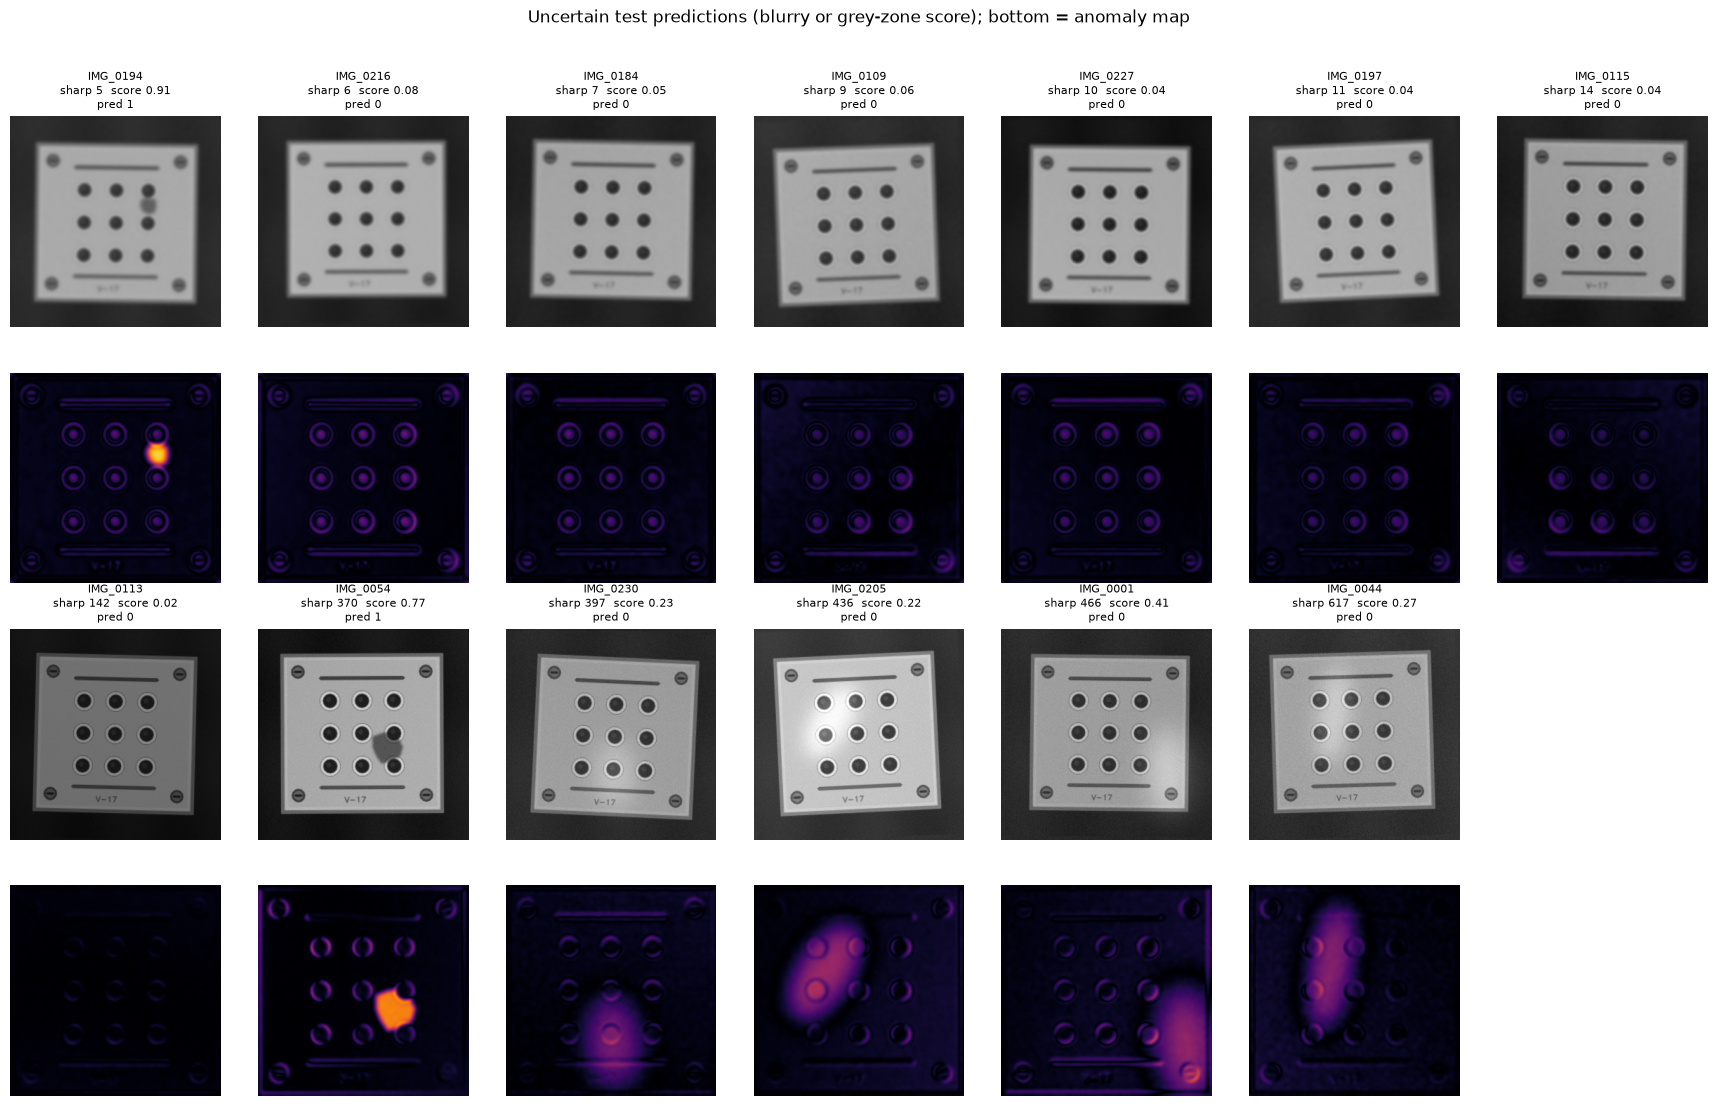

In [29]:
BLUR_LIMIT = 150
test["blurry"] = test.sharpness < BLUR_LIMIT
test["uncertain"] = test.blurry | test.score.between(0.2, 0.8)
for lim in (20, BLUR_LIMIT):
    print(f"sharpness < {lim}: train {int((train.sharpness < lim).sum())} of {len(train)}, "
          f"test {int((test.sharpness < lim).sum())} of {len(test)}")
print(f"test images flagged uncertain: {int(test.uncertain.sum())}")
display(test.loc[test.uncertain, ["image_id", "camera", "exposure_setting", "sharpness", "anomaly_score", "score", "predicted_defect"]]
            .sort_values("sharpness").style.format({"sharpness": "{:.0f}", "anomaly_score": "{:.2f}", "score": "{:.3f}"}).hide(axis="index"))

unc = test[test.uncertain].sort_values("sharpness")
per_row = 7
n_rows = int(np.ceil(len(unc) / per_row))
fig, axes = plt.subplots(2 * n_rows, per_row, figsize=(2.5 * per_row, 5.4 * n_rows))
for a in axes.flat: a.axis("off")
for k, r in enumerate(unc.itertuples()):
    row, col = 2 * (k // per_row), k % per_row
    g = read_gray(r.file)
    axes[row, col].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[row, col].set_title(f"{r.image_id}\nsharp {r.sharpness:.0f}  score {r.score:.2f}\npred {r.predicted_defect}", fontsize=8)
    axes[row + 1, col].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
plt.suptitle("Uncertain test predictions (blurry or grey-zone score); bottom = anomaly map", y=1.02)
plt.tight_layout(); plt.show()

**Notes on the test predictions:**
* The share of predicted defects is in the same range as the verified training rate, so there's no sign of a systematic shift
  in the scores.
* The blurry images get moderately raised scores (≈ 0.7–1.0, against ≈ 0.4 for a typical OK plate) because blur changes the
  look of the hole edges. That isn't enough to cross the cut, so most are predicted OK. The exception is IMG_0194, where a
  blob is visible even through the blur. The opposite risk is real too: **blur can hide a thin scratch or a faint stain**, so a
  "0" on a blurry image means "no defect visible", not "no defect". In production these images should be **re-captured** rather than auto-passed.
  IMG_0113 is flagged because it is very dark (underexposed), not because of blur; its low score is less trustworthy for the same reason.
* Grey-zone scores: IMG_0230, 0205, 0001 and 0044 are **glare / lighting spots** (visible as broad soft blobs in the anomaly map)
  and are correctly kept below the cut. IMG_0054 is a **real stain** and is correctly flagged. These are the images a human should look at first.
* All 13 uncertain images except IMG_0113 come from **CAM-B**, which fits the capture-quality concerns about that camera.

## Part D: checking the results (validation split only)

All metrics below use the **model fit on the dev split only** (Part C), applied to the **51 validation images** it never saw.
They're reported against both label sets:
* `verified_label`: the corrected labels the model was trained on;
* `inspector_label`: the original labels, i.e. how the model looks if the inspector is taken as ground truth.

### D1. Confusion matrix, precision and recall (threshold 0.5)

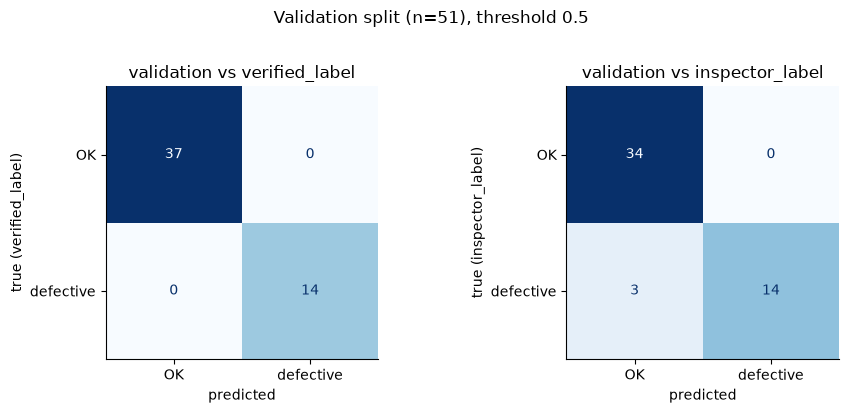

,TP,FP,FN,TN,precision,precision 95% CI,recall,recall 95% CI
verified_label,14,0,0,37,1.000,0.77–1.00,1.000,0.77–1.00
inspector_label,14,0,3,34,1.000,0.77–1.00,0.824,0.57–0.96


In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score
from scipy.stats import beta

def clopper_pearson(k, n, alpha=0.05):
    # exact 95% CI for a proportion k/n
    lo = beta.ppf(alpha / 2, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - alpha / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi

def evaluate(df, label, thr):
    y, p = df[label], (df.score_dev_model >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    pl, ph = clopper_pearson(tp, tp + fp); rl, rh = clopper_pearson(tp, tp + fn)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": tp / (tp + fp) if tp + fp else np.nan, "precision 95% CI": f"{pl:.2f}–{ph:.2f}",
            "recall": tp / (tp + fn), "recall 95% CI": f"{rl:.2f}–{rh:.2f}"}

dev, val = train[train.split == "dev"], train[train.split == "val"]   # re-slice: now includes score_dev_model
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, label in zip(axes, ["verified_label", "inspector_label"]):
    pred = (val.score_dev_model >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(val[label], pred, labels=[0, 1]),
                           display_labels=["OK", "defective"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"validation vs {label}"); ax.set_xlabel("predicted"); ax.set_ylabel(f"true ({label})")
plt.suptitle(f"Validation split (n={len(val)}), threshold {THRESHOLD}", y=1.02); plt.tight_layout(); plt.show()

display(pd.DataFrame({lab: evaluate(val, lab, THRESHOLD) for lab in ["verified_label", "inspector_label"]}).T
          .style.format({"precision": "{:.3f}", "recall": "{:.3f}"}))

**Reading the results:**
* **Against the verified labels:** all 14 defects are caught and there are no false alarms (precision = recall = 1.0).
  That doesn't mean the model is perfect. With only 14 defective validation images, the exact 95% interval for recall still
  reaches down to about 0.77. On top of that, these labels were partly corrected *toward* the model (Part B4), which flatters the numbers.
* **Against the original inspector labels:** precision stays 1.0, but recall drops to 0.82. The 3 "missed defects" are exactly the 3
  validation images whose stain label was judged invisible in B4 (IMG_0111, 0025, 0039). So in this split, every disagreement with the
  inspector is an image where no defect can be seen.
* The honest summary: **the true recall is probably high, but this validation set is too small and too easy to pin it down.**

### D2. Comparing two thresholds
The threshold sets the trade-off between missed defects (FN) and false alarms (FP):
* **0.5**: the default, balanced cut (anomaly_score ≈ 1.81);
* **0.1**: a "screening" cut (anomaly_score ≈ 0.95), which flags anything even mildly unusual for a human to check.

In [31]:
THRESHOLDS = [0.5, 0.1]
for thr in THRESHOLDS:
    print(f"threshold {thr}  <=>  anomaly_score >= {(np.log(thr / (1 - thr)) - model.intercept_[0]) / model.coef_[0, 0]:.2f}")
rows = []
for thr in THRESHOLDS:
    for split_name, df in [("validation", val), ("dev (for reference)", dev)]:
        for lab in ["verified_label", "inspector_label"]:
            rows.append({"threshold": thr, "split": split_name, "labels": lab, **evaluate(df, lab, thr)})
display(pd.DataFrame(rows).set_index(["threshold", "split", "labels"])
          .style.format({"precision": "{:.3f}", "recall": "{:.3f}"}))

threshold 0.5  <=>  anomaly_score >= 1.81
threshold 0.1  <=>  anomaly_score >= 0.95


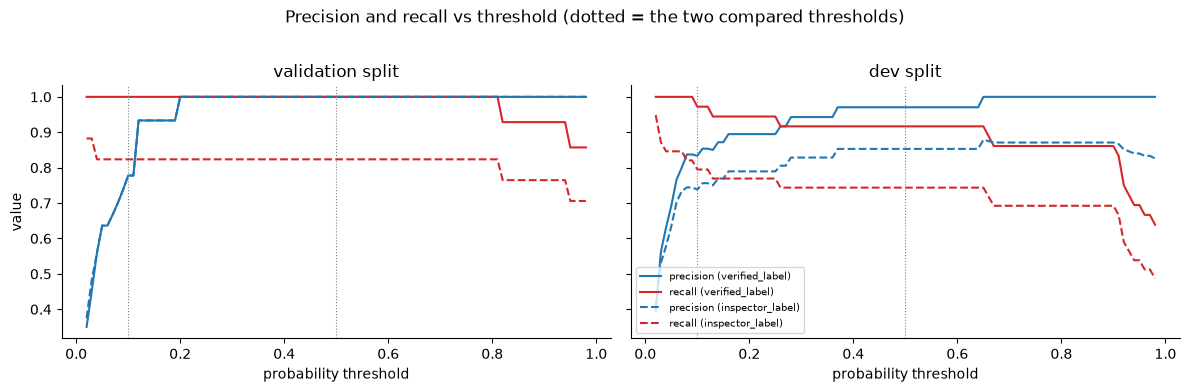

In [32]:
thr_grid = np.linspace(0.02, 0.98, 97)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, df) in zip(axes, [("validation", val), ("dev", dev)]):
    for lab, ls in [("verified_label", "-"), ("inspector_label", "--")]:
        P = [precision_score(df[lab], df.score_dev_model >= t, zero_division=1) for t in thr_grid]
        R = [recall_score(df[lab], df.score_dev_model >= t) for t in thr_grid]
        ax.plot(thr_grid, P, ls, color="tab:blue", label=f"precision ({lab})")
        ax.plot(thr_grid, R, ls, color="tab:red", label=f"recall ({lab})")
    for t in THRESHOLDS: ax.axvline(t, color="gray", lw=0.8, ls=":")
    ax.set_title(f"{name} split"); ax.set_xlabel("probability threshold")
axes[0].set_ylabel("value"); axes[1].legend(fontsize=7.5, loc="lower left")
plt.suptitle("Precision and recall vs threshold (dotted = the two compared thresholds)", y=1.02); plt.tight_layout(); plt.show()

**Threshold comparison:**
* On **validation**, every threshold between ≈0.2 and ≈0.8 gives the same result, because there is a wide empty gap between the
  highest-scoring OK image (0.19, a glare spot) and the lowest-scoring defect (0.81, a stain). Lowering the cut to **0.1** catches nothing new
  and only adds **false alarms**: OK images with glare or lighting spots.
* On **dev**, the 0.5 cut misses 3 verified defects, including the thin scratch IMG_0101. The 0.1 cut recovers part of them, at the cost of extra false alarms.
* **Recommendation:** keep **0.5** for the automatic decision. In a screening setting where a missed defect is much more costly than
  a manual check, 0.1 is reasonable *if* someone reviews the extra flags, which are mostly glare.

### D3. One error and one uncertain prediction, explained

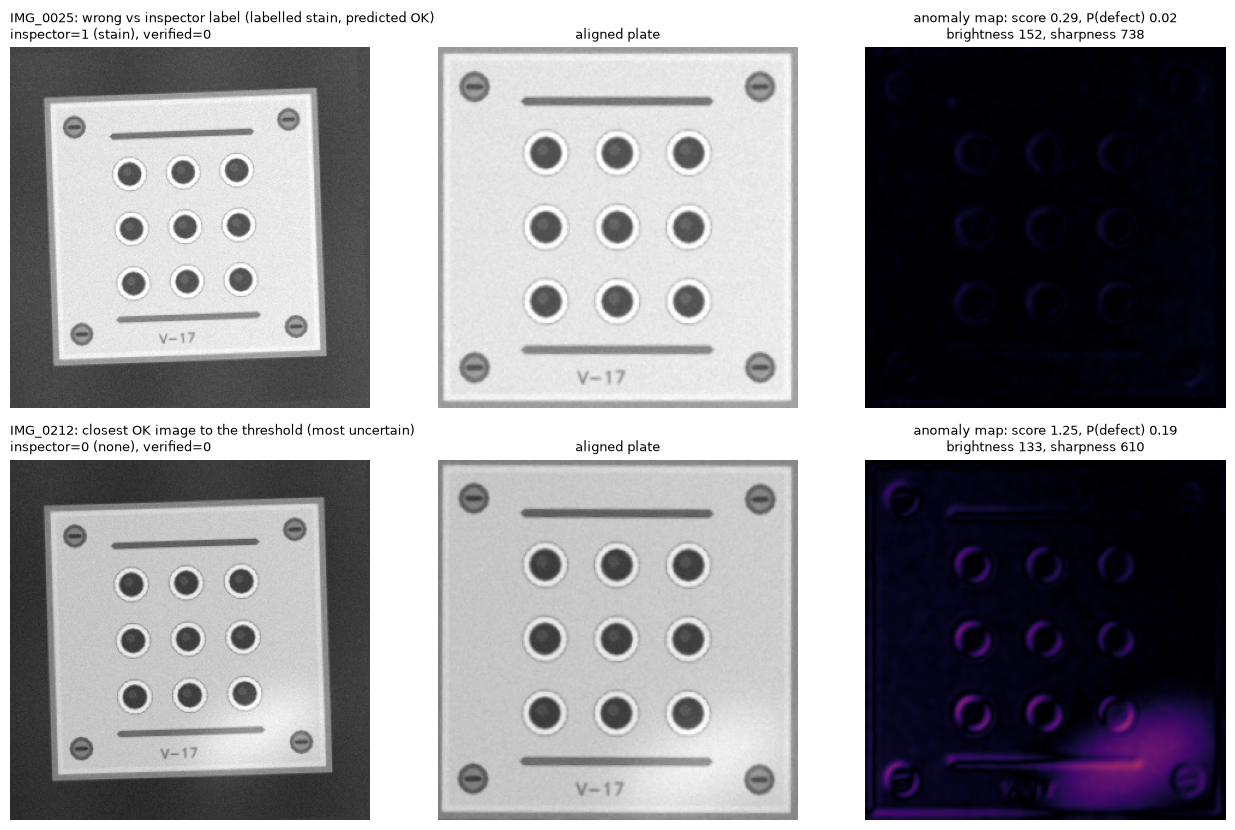

validation brightness, median / max: 115 / 165


In [33]:
pick = {
    "IMG_0025": "wrong vs inspector label (labelled stain, predicted OK)",
    "IMG_0212": "closest OK image to the threshold (most uncertain)",
}
fig, axes = plt.subplots(2, 3, figsize=(13, 8.4))
for row, (iid, why) in enumerate(pick.items()):
    r = train.set_index("image_id").loc[iid]
    g = read_gray(r.file)
    axes[row, 0].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"{iid}: {why}\ninspector={r.inspector_label} ({r.inspector_type}), verified={r.verified_label}", fontsize=9, loc="left")
    axes[row, 1].imshow(align_plate(g), cmap="gray", vmin=0, vmax=255); axes[row, 1].set_title("aligned plate", fontsize=9)
    axes[row, 2].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
    axes[row, 2].set_title(f"anomaly map: score {r.anomaly_score:.2f}, P(defect) {r.score_dev_model:.2f}\n"
                           f"brightness {r.brightness:.0f}, sharpness {r.sharpness:.0f}", fontsize=9)
for a in axes.flat: a.axis("off")
plt.tight_layout(); plt.show()
print("validation brightness, median / max:", f"{val.brightness.median():.0f} / {val.brightness.max():.0f}")

**IMG_0025: labelled "stain" by the inspector, predicted OK (P = 0.02).**
The plate shows no stain, and the anomaly map is flat. The likely explanation is a **labelling error** (it is one of the batch A stain
labels judged invisible in B4). There is a second possibility, and it is a real limitation: this image is **strongly overexposed**
(one of the brightest in validation). Overexposure compresses the grey levels of the plate, so a *faint, light* stain could be washed out
before the model ever sees it. The brightness normalisation can't recover detail that the camera clipped.
So this is either an inspector error or a capture problem, and neither is something a better model could fix. The fix is a re-inspection, or re-capturing with the right exposure.

**IMG_0212: OK, but the most uncertain OK prediction (P = 0.19).**
The anomaly map shows a broad, soft blob in the lower-right corner: a **glare / lighting reflection**, not a defect.
The score comes from a real limitation of the feature: the brightness normalisation is *global*, so a *local* light change still
counts as a deviation from the template. It stays below the cut because glare is diffuse while real defects are sharp-edged, but
a stronger reflection could cross it. A local normalisation (e.g. dividing by a heavily blurred copy of the image), or more uniform
lighting at the station, would reduce this failure mode.

**Known limitations of the solution:**
1. Thin, low-contrast defects can score low (the dev scratch IMG_0101), because smoothing spreads a thin line out.
2. Glare and uneven lighting raise the score of OK parts (D3, and the grey zone in Part C).
3. Blurry or badly exposed images hide defects. The model can only say "no defect *visible*".
4. The validation set is small (51) and its labels were partly corrected using the model's own disagreements, so the metrics are optimistic.